In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Financial transaction analysis
Volumes, temporal rhythm, customer concentration and the monetary impact of fraud.

In [2]:
df = load_clean(); df['timestamp'] = pd.to_datetime(df.timestamp); df['day'] = df.timestamp.dt.date; df['hour'] = df.timestamp.dt.hour; df['dow'] = df.timestamp.dt.day_name()

<Axes: title={'center': 'Frauds per day'}, xlabel='day'>

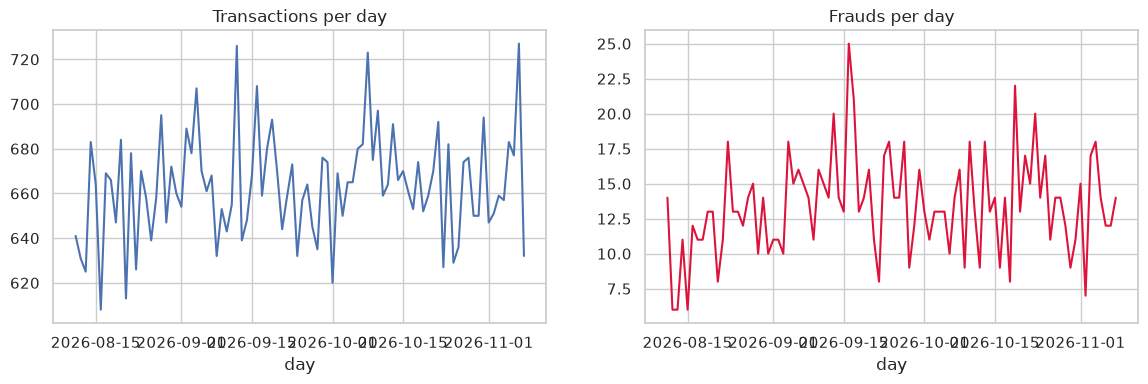

In [3]:
daily = df.groupby('day').agg(n=('amount','size'), value=('amount','sum'), frauds=('is_fraud','sum'))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8)); daily.n.plot(ax=ax[0], title='Transactions per day'); daily.frauds.plot(ax=ax[1], color='crimson', title='Frauds per day')

Text(0.5, 1.0, 'Transaction volume: weekday x hour')

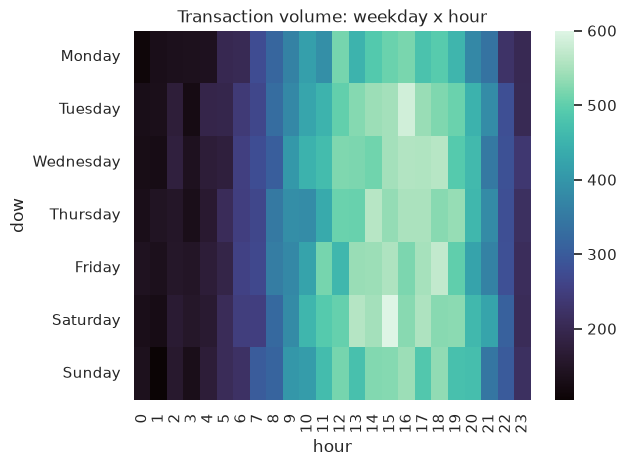

In [4]:
pt = df.pivot_table(index='dow', columns='hour', values='amount', aggfunc='size').reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
sns.heatmap(pt, cmap='mako'); plt.title('Transaction volume: weekday x hour')

In [5]:
df.groupby('channel').amount.describe(percentiles=[.5,.9,.99]).round(2)

,count,mean,std,min,50%,90%,99%,max
channel,,,,,,,,
atm,3017.0,73.97,95.05,2.66,47.15,154.46,458.23,1874.20
mobile_app,26934.0,75.12,99.06,0.93,46.86,158.66,463.97,2855.34
pos,14825.0,70.77,85.96,1.10,46.33,149.15,389.79,2411.23
web,14906.0,71.55,91.16,0.53,45.36,153.92,435.56,2531.85


In [6]:
per_c = df.groupby('customer_id').amount.sum().sort_values(ascending=False)
share = per_c.cumsum() / per_c.sum()
print('Top 10% of customers account for', f'{share.iloc[int(len(share)*.1)]:.1%}', 'of value')

Top 10% of customers account for 28.2% of value


In [7]:
impact = df.groupby('is_fraud').amount.agg(['count','sum','mean','median']); impact

,count,sum,mean,median
is_fraud,,,,
0,58476,4129174.29,70.613145,46.155
1,1206,233077.39,193.264834,86.950


In [8]:
px.treemap(df[df.is_fraud==1], path=['channel','merchant_category'], values='amount', title='Where fraud value concentrates')